APARTADO 2.1. ACRIMA PRUEBA SEGUNDA

In [ ]:
import os
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ModelCheckpoint, CSVLogger
from tensorflow.keras.layers import GlobalAveragePooling2D, BatchNormalization
# === Rutas
BASE_PATH = os.path.expanduser("~/Desktop/ACRIMA/PARTITIONED")
TRAIN_DIR = os.path.join(BASE_PATH, "Training")

# === Generador con augmentación y split
train_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.vgg16.preprocess_input,
    rotation_range=15,
    zoom_range=0.15,
    horizontal_flip=True,
    validation_split=0.2
)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    subset='training',
    shuffle=True,
    seed=42
)

val_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    subset='validation',
    shuffle=False,
    seed=42
)



# 1. Cargamos VGG16 como extractor de características
base_model = VGG16(include_top=False, weights='imagenet', input_shape=(224, 224, 3))

# 2. Congelamos las capas convolucionales
for layer in base_model.layers:
    layer.trainable = False  

# 3. Añadimos una nueva cabeza densa personalizada a la red
#    si aumentamos el tamaño de la cabeza puede dar overfitting

x = GlobalAveragePooling2D()(base_model.output)
x = BatchNormalization()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x) # si reducimos el dropout puede dar overfitting
x = Dense(64, activation='relu')(x)
x = Dropout(0.2)(x)
output = Dense(1, activation='sigmoid')(x) # salida binaria

# 4. Creamos el modelo final
model = Model(inputs=base_model.input, outputs=output)

# 5. Compilamos el modelo
model.compile(optimizer=Adam(1e-4), loss='binary_crossentropy', metrics=['accuracy'])

# 6. Resumen del modelo
model.summary()

# 7. Callbacks para guardar el mejor modelo y registrar el entrenamiento
checkpoint = ModelCheckpoint(
    filepath=os.path.expanduser("~/Desktop/best_model_realista.h5"),
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

# 8. Logger para registrar el entrenamiento en CSV
csv_logger = CSVLogger(os.path.expanduser("~/Desktop/training_log_realista.csv"))




Found 452 images belonging to 2 classes.
Found 112 images belonging to 2 classes.


2025-06-19 18:15:44.120881: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3
2025-06-19 18:15:44.120909: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2025-06-19 18:15:44.120913: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.33 GB
2025-06-19 18:15:44.120932: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2025-06-19 18:15:44.120944: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [2]:
from tensorflow.keras.callbacks import LambdaCallback

batch_acc_list = []

batch_logger = LambdaCallback(
    on_batch_end=lambda batch, logs: batch_acc_list.append(logs.get('accuracy'))
)


In [3]:

# === Entrenamiento
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=80,
    callbacks=[checkpoint, csv_logger, batch_logger],
    verbose=1
)

/opt/anaconda3/envs/vgg16_env/lib/python3.9/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/80


2025-06-19 18:15:48.992267: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 807ms/step - accuracy: 0.4887 - loss: 1.1174
Epoch 1: val_accuracy improved from -inf to 0.68750, saving model to /Users/valeriabaz/Desktop/best_model_realista.h5


15/15 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.4907 - loss: 1.1156 - val_accuracy: 0.6875 - val_loss: 0.6196
Epoch 2/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 835ms/step - accuracy: 0.6313 - loss: 0.8719
Epoch 2: val_accuracy improved from 0.68750 to 0.71429, saving model to /Users/valeriabaz/Desktop/best_model_realista.h5


...

15/15 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.8959 - loss: 0.2536 - val_accuracy: 0.9286 - val_loss: 0.2169
Epoch 24/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 817ms/step - accuracy: 0.8650 - loss: 0.2554
Epoch 24: val_accuracy did not improve from 0.92857
15/15 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.8650 - loss: 0.2581 - val_accuracy: 0.8839 - val_loss: 0.2594
Epoch 25/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 818ms/step - accuracy: 0.8978 - loss: 0.2533
Epoch 25: val_accuracy did not improve from 0.92857
15/15 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.8964 - loss: 0.2553 - val_accuracy: 0.9018 - val_loss: 0.2467
Epoch 26/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 824ms/step - accuracy: 0.8897 - loss: 0.2552
Epoch 26: val_accuracy did not improve from 0.92857
15/15 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.8891 - loss: 0.2561 - val_accuracy: 0.9018 - val_loss: 0.2402
Epoch 27/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 811ms/step - accuracy: 0.8668 - loss: 0.3348
Epoch 27: val_accuracy did not impro

15/15 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.9032 - loss: 0.2337 - val_accuracy: 0.9375 - val_loss: 0.1559
Epoch 36/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 825ms/step - accuracy: 0.8795 - loss: 0.2417
Epoch 36: val_accuracy did not improve from 0.93750
15/15 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.8798 - loss: 0.2424 - val_accuracy: 0.9286 - val_loss: 0.1749
Epoch 37/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 821ms/step - accuracy: 0.9277 - loss: 0.1863
Epoch 37: val_accuracy did not improve from 0.93750
15/15 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.9274 - loss: 0.1875 - val_accuracy: 0.9375 - val_loss: 0.1898
Epoch 38/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 823ms/step - accuracy: 0.9264 - loss: 0.1938
Epoch 38: val_accuracy did not improve from 0.93750
15/15 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.9262 - loss: 0.1938 - val_accuracy: 0.9286 - val_loss: 0.2015
Epoch 39/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 834ms/step - accuracy: 0.9045 - loss: 0.2592
Epoch 39: val_accuracy did not impro

15/15 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.8883 - loss: 0.2412 - val_accuracy: 0.9464 - val_loss: 0.1646
Epoch 50/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 829ms/step - accuracy: 0.9168 - loss: 0.1855
Epoch 50: val_accuracy did not improve from 0.94643
15/15 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.9180 - loss: 0.1847 - val_accuracy: 0.9196 - val_loss: 0.1827
Epoch 51/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 828ms/step - accuracy: 0.9136 - loss: 0.1851
Epoch 51: val_accuracy did not improve from 0.94643
15/15 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.9139 - loss: 0.1851 - val_accuracy: 0.9464 - val_loss: 0.1857
Epoch 52/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 818ms/step - accuracy: 0.9322 - loss: 0.2063
Epoch 52: val_accuracy did not improve from 0.94643
15/15 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.9320 - loss: 0.2053 - val_accuracy: 0.9464 - val_loss: 0.1733
Epoch 53/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 822ms/step - accuracy: 0.9421 - loss: 0.1202
Epoch 53: val_accuracy did not impro

15/15 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.9000 - loss: 0.2129 - val_accuracy: 0.9554 - val_loss: 0.1440
Epoch 59/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 808ms/step - accuracy: 0.9634 - loss: 0.1365
Epoch 59: val_accuracy did not improve from 0.95536
15/15 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.9627 - loss: 0.1384 - val_accuracy: 0.9286 - val_loss: 0.1772
Epoch 60/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 865ms/step - accuracy: 0.9171 - loss: 0.2968
Epoch 60: val_accuracy did not improve from 0.95536
15/15 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.9172 - loss: 0.2930 - val_accuracy: 0.9196 - val_loss: 0.1828
Epoch 61/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 799ms/step - accuracy: 0.9378 - loss: 0.1611
Epoch 61: val_accuracy did not improve from 0.95536
15/15 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.9364 - loss: 0.1638 - val_accuracy: 0.9375 - val_loss: 0.1629
Epoch 62/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 801ms/step - accuracy: 0.9287 - loss: 0.1681
Epoch 62: val_accuracy did not impro

15/15 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.9156 - loss: 0.2449 - val_accuracy: 0.9643 - val_loss: 0.1438
Epoch 74/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 822ms/step - accuracy: 0.9391 - loss: 0.1354
Epoch 74: val_accuracy did not improve from 0.96429
15/15 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.9383 - loss: 0.1367 - val_accuracy: 0.9107 - val_loss: 0.2358
Epoch 75/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 807ms/step - accuracy: 0.9275 - loss: 0.1575
Epoch 75: val_accuracy did not improve from 0.96429
15/15 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.9279 - loss: 0.1573 - val_accuracy: 0.9196 - val_loss: 0.2318
Epoch 76/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 809ms/step - accuracy: 0.9197 - loss: 0.1941
Epoch 76: val_accuracy did not improve from 0.96429
15/15 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.9199 - loss: 0.1930 - val_accuracy: 0.9464 - val_loss: 0.1700
Epoch 77/80
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 779ms/step - accuracy: 0.9318 - loss: 0.1744
Epoch 77: val_accuracy did not impro

In [7]:
from scipy.stats import ttest_ind

# === Parámetros de análisis
alpha = 0.05
difference_threshold = 0.02
window_size = 5

overfit_epochs = []

# ❗ Ya son arrays, no uses .to_numpy()
train_array = train_acc
val_array = val_acc

for i in range(window_size, len(train_array)):
    train_window = train_array[i - window_size:i]
    val_window = val_array[i - window_size:i]

    t_stat, p_val = ttest_ind(train_window, val_window, equal_var=False)
    diff = np.mean(train_window) - np.mean(val_window)

    if (diff > difference_threshold) and (p_val < alpha):
        overfit_epochs.append(epochs[i])

# === Mostrar resultado
if overfit_epochs:
    print(f"⚠️ Sobreajuste detectado a partir de la época: {overfit_epochs[0]}")
else:
    print("✅ No se detectó sobreajuste estadísticamente significativo.")


✅ No se detectó sobreajuste estadísticamente significativo.


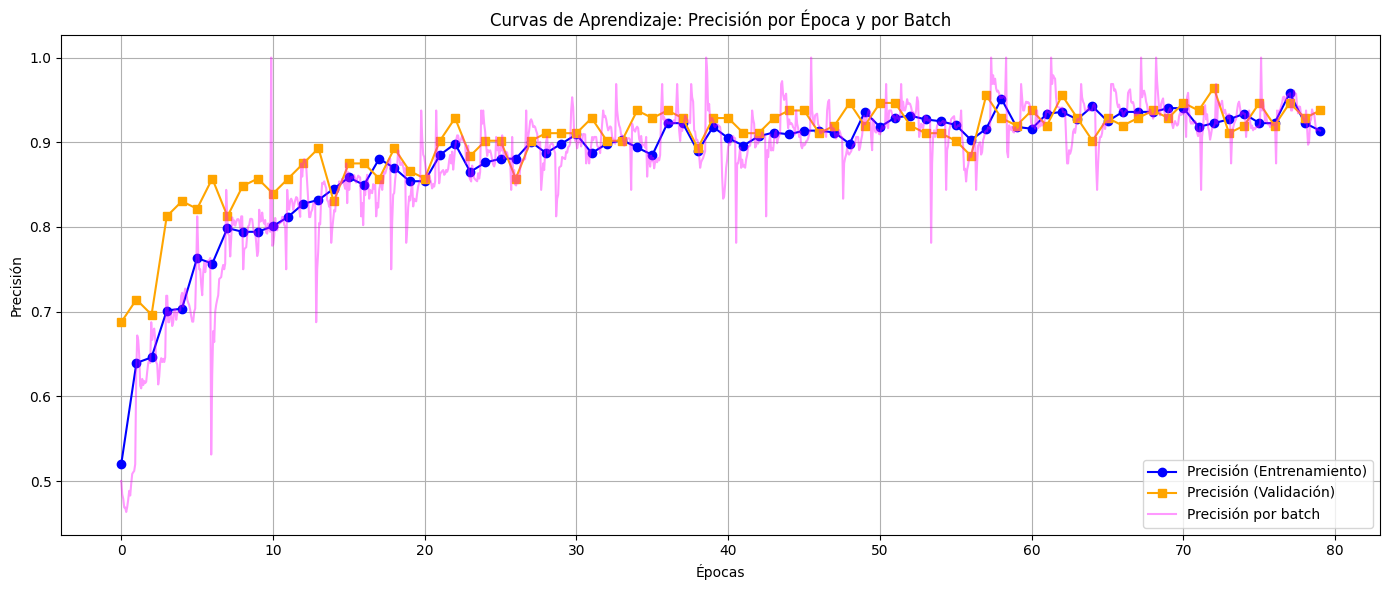

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

# === Cargar los datos por época
log_path = os.path.expanduser("~/Desktop/training_log_realista.csv")
log = pd.read_csv(log_path)
epochs = log['epoch']
train_acc = log['accuracy']
val_acc = log['val_accuracy']

# === Construir curva de precisión por batch (ya capturada durante entrenamiento)
# Interpolamos para que encaje en el eje
batch_steps = len(batch_acc_list)
x_batch = np.linspace(0, len(epochs)-1, batch_steps)

# === Gráfica
plt.figure(figsize=(14, 6))
plt.plot(epochs, train_acc, label='Precisión (Entrenamiento)', color='blue', marker='o')
plt.plot(epochs, val_acc, label='Precisión (Validación)', color='orange', marker='s')
plt.plot(x_batch, batch_acc_list, label='Precisión por batch', color='fuchsia', alpha=0.4)

plt.title("Curvas de Aprendizaje: Precisión por Época y por Batch")
plt.xlabel("Épocas")
plt.ylabel("Precisión")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()


No se detectó sobreajuste estadísticamente significativo.


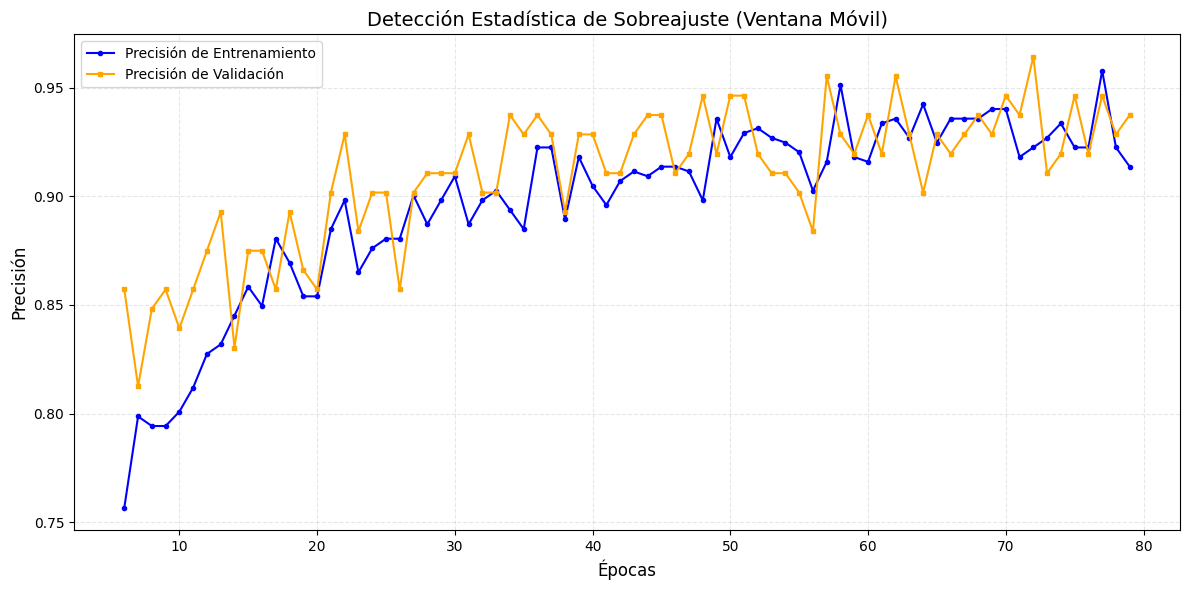

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

# === Cargar CSV del entrenamiento realista
log = pd.read_csv('~/Desktop/training_log_realista.csv')

# Recortar si se desea
start_epoch = 6
log = log[log['epoch'] >= start_epoch].reset_index(drop=True)

# Extraer datos
train_acc = log['accuracy'].to_numpy()
val_acc = log['val_accuracy'].to_numpy()
epochs = log['epoch'].to_numpy()

# === Parámetros del análisis
alpha = 0.05                  # nivel de significancia
window_size = 5              # tamaño de ventana
difference_threshold = 0.02  # umbral clínicamente relevante

# === Detectar sobreajuste
overfit_epochs = []

for i in range(window_size, len(train_acc)):
    train_window = train_acc[i - window_size:i]
    val_window = val_acc[i - window_size:i]

    t_stat, p_val = ttest_ind(train_window, val_window, equal_var=False)
    diff = np.mean(train_window) - np.mean(val_window)

    if (diff > difference_threshold) and (p_val < alpha):
        overfit_epochs.append(epochs[i])

# === Resultado
if overfit_epochs:
    print(f"Sobreajuste detectado a partir de la época: {overfit_epochs[0]}")
else:
    print("No se detectó sobreajuste estadísticamente significativo.")

# === Graficar curvas con marcas
plt.figure(figsize=(12, 6))
plt.plot(epochs, train_acc, label='Precisión de Entrenamiento', color='blue', marker='o', markersize=3)
plt.plot(epochs, val_acc, label='Precisión de Validación', color='orange', marker='s', markersize=3)

# Líneas verticales donde se detecta sobreajuste
for i, e in enumerate(overfit_epochs):
    plt.axvline(x=e, color='red', linestyle='--', alpha=0.5, linewidth=1,
                label='Sobreajuste Estadístico' if i == 0 else "")

plt.title("Detección Estadística de Sobreajuste (Ventana Móvil)", fontsize=14)
plt.xlabel("Épocas", fontsize=12)
plt.ylabel("Precisión", fontsize=12)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()


Epoch 5: p = 0.0465, diff = -0.1062
Epoch 6: p = 0.0515, diff = -0.0843
Epoch 7: p = 0.0360, diff = -0.0894
Epoch 8: p = 0.0083, diff = -0.0821
Epoch 9: p = 0.0105, diff = -0.0707
Epoch 10: p = 0.0020, diff = -0.0579
Epoch 11: p = 0.0017, diff = -0.0539
Epoch 12: p = 0.0043, diff = -0.0429
Epoch 13: p = 0.0004, diff = -0.0496
Epoch 14: p = 0.0027, diff = -0.0510
Epoch 15: p = 0.0369, diff = -0.0355
Epoch 16: p = 0.0485, diff = -0.0311
Epoch 17: p = 0.0607, diff = -0.0272
Epoch 18: p = 0.3599, diff = -0.0130
Epoch 19: p = 0.6741, diff = -0.0055
Epoch 20: p = 0.2214, diff = -0.0108
Epoch 21: p = 0.3863, diff = -0.0081
Epoch 22: p = 0.5903, diff = -0.0064
Epoch 23: p = 0.3042, diff = -0.0172
Epoch 24: p = 0.3300, diff = -0.0163
Epoch 25: p = 0.2197, diff = -0.0190
Epoch 26: p = 0.0379, diff = -0.0226
Epoch 27: p = 0.3065, diff = -0.0146
Epoch 28: p = 0.4305, diff = -0.0088
Epoch 29: p = 0.3921, diff = -0.0097
Epoch 30: p = 0.5440, diff = -0.0070
Epoch 31: p = 0.7994, diff = -0.0031
Epoch 

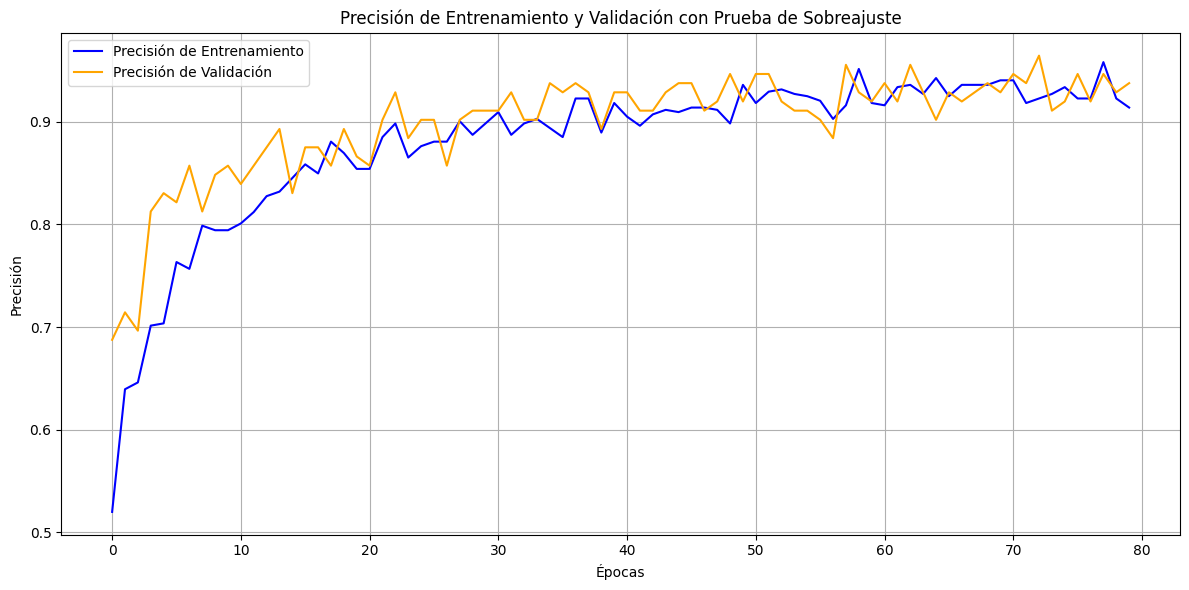

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

# === Parámetros del análisis
alpha = 0.05
difference_threshold = 0.02
window_size = 5

# === Cargar log del entrenamiento
log = pd.read_csv('~/Desktop/training_log_realista.csv')
train_acc = log['accuracy'].to_numpy()
val_acc = log['val_accuracy'].to_numpy()
epochs = log['epoch'].to_numpy()

significant_epochs = []

for i in range(window_size, len(train_acc)):
    train_window = train_acc[i - window_size:i]
    val_window = val_acc[i - window_size:i]

    if len(train_window) >= 2 and len(val_window) >= 2:
        t_stat, p_val = ttest_ind(train_window, val_window, equal_var=False)
        diff = np.mean(train_window) - np.mean(val_window)

        print(f"Epoch {epochs[i]}: p = {p_val:.4f}, diff = {diff:.4f}")

        if (p_val < alpha) and (diff > difference_threshold):
            significant_epochs.append(epochs[i])

# === Gráfica
plt.figure(figsize=(12, 6))
plt.plot(epochs, train_acc, label='Precisión de Entrenamiento', color='blue')
plt.plot(epochs, val_acc, label='Precisión de Validación', color='orange')

for i, ep in enumerate(significant_epochs):
    plt.axvline(x=ep, color='red', linestyle='--', alpha=0.5, label='Sobreajuste Estadístico' if i == 0 else "")

plt.title("Precisión de Entrenamiento y Validación con Prueba de Sobreajuste")
plt.xlabel("Épocas")
plt.ylabel("Precisión")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [9]:
import pandas as pd
import numpy as np
from scipy.stats import ttest_ind

# === Cargar el log
log = pd.read_csv('~/Desktop/training_log_realista.csv')
train_acc = log['accuracy'].to_numpy()
val_acc = log['val_accuracy'].to_numpy()
epochs = log['epoch'].to_numpy()

# === Configuración de ventana y resultados
w = 5
alpha = 0.05

results = []

for i in range(w, len(train_acc)):
    train_window = train_acc[i - w:i]
    val_window = val_acc[i - w:i]

    t_stat, p_val = ttest_ind(train_window, val_window, equal_var=False)
    diff_mean = np.mean(train_window) - np.mean(val_window)

    results.append({
        'Epoch': epochs[i],
        'p-value': round(p_val, 4),
        'Difference': round(diff_mean, 4)
    })




Found 141 images belonging to 2 classes.


/opt/anaconda3/envs/vgg16_env/lib/python3.9/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
2025-06-25 19:21:26.596905: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 263ms/step - accuracy: 0.8790 - loss: 0.3128
[RESULTADO] Accuracy: 0.9078
[RESULTADO] Loss: 0.2568
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 266ms/step

Matriz de Confusión:
Normal clasificado como normal (TN): 69
Normal clasificado como glaucoma (FP): 10
Glaucoma clasificado como normal (FN): 3
Glaucoma clasificado como glaucoma (TP): 59

Accuracy: 0.91
Precisión (PPV): 0.96
Sensibilidad (TPR): 0.87
Especificidad (TNR): 0.87


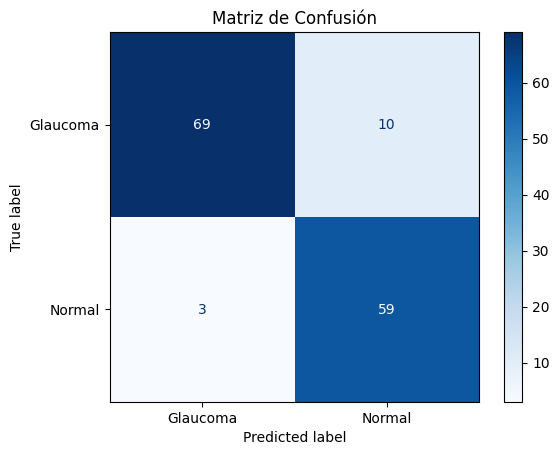

Unicos en y_true: [0 1]

Índice de Youden máximo: 0.8906
Umbral óptimo (threshold): 0.9315
Sensibilidad óptima: 0.9032
Especificidad óptima: 0.9873


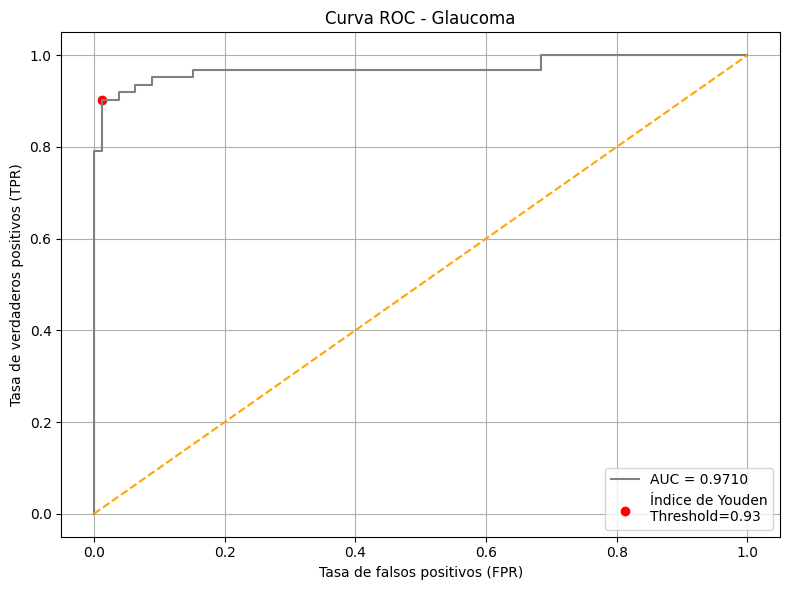

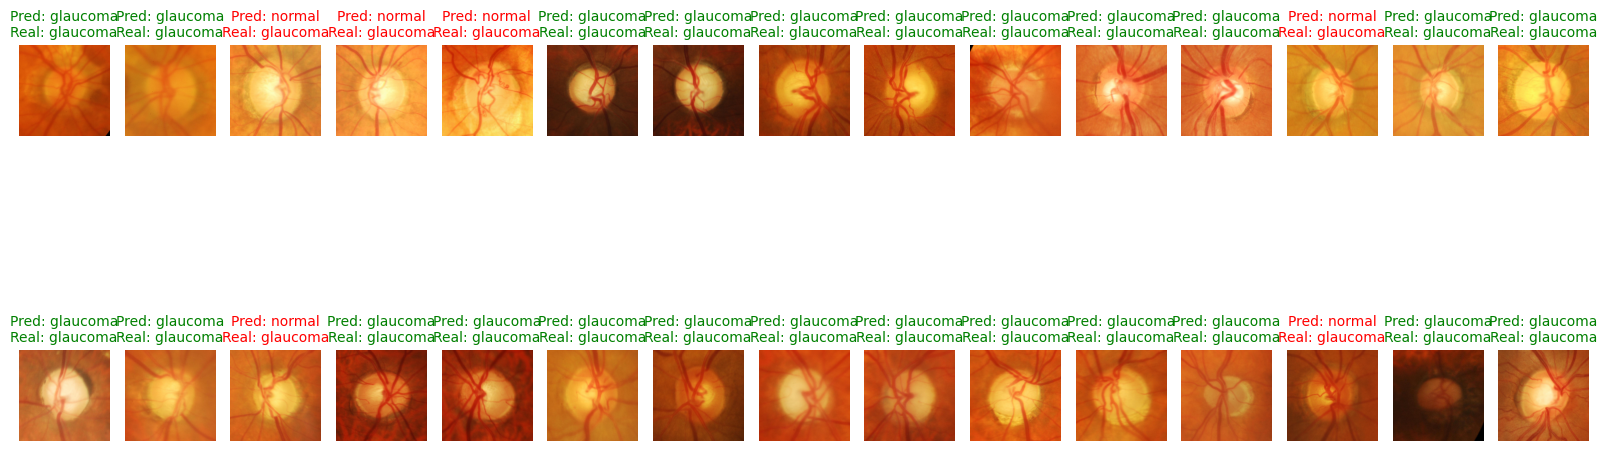

In [5]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score, roc_curve, auc
from sklearn.metrics import ConfusionMatrixDisplay

# === Cargar modelo
model = load_model(os.path.expanduser("~/Desktop/best_model_realista.h5"))

# === Preparar conjunto de test
TEST_PATH = os.path.expanduser("~/Desktop/ACRIMA/PARTITIONED/Testing")
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

test_datagen = ImageDataGenerator(preprocessing_function=tf.keras.applications.vgg16.preprocess_input)

test_generator = test_datagen.flow_from_directory(
    TEST_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

# === Evaluación
loss, acc = model.evaluate(test_generator, verbose=1)
print(f"[RESULTADO] Accuracy: {acc:.4f}")
print(f"[RESULTADO] Loss: {loss:.4f}")

# === Predicciones
y_true = test_generator.classes
y_prob = model.predict(test_generator).ravel()
y_pred = (y_prob > 0.5).astype(int)

# === Matriz de confusión y métricas
cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()

ppv = precision_score(y_true, y_pred, pos_label=0)
recall = recall_score(y_true, y_pred, pos_label=0)
specificity = tn / (tn + fp)

print("\nMatriz de Confusión:")
print(f"Normal clasificado como normal (TN): {tn}")
print(f"Normal clasificado como glaucoma (FP): {fp}")
print(f"Glaucoma clasificado como normal (FN): {fn}")
print(f"Glaucoma clasificado como glaucoma (TP): {tp}")
print(f"\nAccuracy: {acc:.2f}")
print(f"Precisión (PPV): {ppv:.2f}")
print(f"Sensibilidad (TPR): {recall:.2f}")
print(f"Especificidad (TNR): {specificity:.2f}")

# === Mostrar matriz visual
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Glaucoma', 'Normal'])
disp.plot(cmap='Blues')
plt.title("Matriz de Confusión")
plt.show()

# === Curva ROC + Índice de Youden
# Confirmar que y_true está en [0, 1]
print("Unicos en y_true:", np.unique(y_true))

# Asegúrate que estás pasando y_prob directamente
fpr, tpr, thresholds = roc_curve(y_true, y_prob, pos_label=1)  # porque parece que el modelo está interpretando 1 como glaucoma
roc_auc = auc(fpr, tpr)


# Youden
youden_index = tpr - fpr
optimal_idx = np.argmax(youden_index)
optimal_threshold = thresholds[optimal_idx]

print(f"\nÍndice de Youden máximo: {youden_index[optimal_idx]:.4f}")
print(f"Umbral óptimo (threshold): {optimal_threshold:.4f}")
print(f"Sensibilidad óptima: {tpr[optimal_idx]:.4f}")
print(f"Especificidad óptima: {1 - fpr[optimal_idx]:.4f}")

# Gráfica ROC
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}", color='grey')
plt.plot([0, 1], [0, 1], linestyle='--', color='orange')
plt.scatter(fpr[optimal_idx], tpr[optimal_idx], color='red', label=f"Índice de Youden\nThreshold={optimal_threshold:.2f}")
plt.title("Curva ROC - Glaucoma")
plt.xlabel("Tasa de falsos positivos (FPR)")
plt.ylabel("Tasa de verdaderos positivos (TPR)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# === Visualizar imágenes clasificadas
filenames = test_generator.filenames
class_indices = test_generator.class_indices
image_paths = [os.path.join(test_generator.directory, fname) for fname in filenames]

def mostrar_predicciones(n=10):
    plt.figure(figsize=(16, 8))
    for i in range(n):
        idx = i
        img_path = os.path.join(test_generator.directory, filenames[idx])
        img = image.load_img(img_path, target_size=IMG_SIZE)
        plt.subplot(2, n//2, i+1)
        plt.imshow(img)
        plt.axis('off')
        pred = "glaucoma" if y_pred[idx] == 0 else "normal"
        real = "glaucoma" if y_true[idx] == 0 else "normal"
        color = 'green' if pred == real else 'red'
        plt.title(f"Pred: {pred}\nReal: {real}", color=color, fontsize=10)
    plt.tight_layout()
    plt.show()

# Mostrar
mostrar_predicciones(n=30)


# <span style="color:violet; font-size:28px"> PROBAR EL RENDIMIENTO DE LA RED ENTRENADA CON ACRIMA SOBRE LA BBDD RIM ONE


In [6]:
import os

# Rutas originales dentro de mi ordenador
base_path = '/Users/valeriabaz/Desktop/Dataset-4 MIAG 2'
normal_path = os.path.join(base_path, 'Normal')
glaucoma_path = os.path.join(base_path, 'Glaucoma')

# Función para listar imágenes .jpg en una carpeta
def listar_jpgs(directorio):
    return sorted([
        f for f in os.listdir(directorio)
        if f.lower().endswith('.jpg') and os.path.isfile(os.path.join(directorio, f))
    ])

# Listado de archivos que sean válidos
jpgs_normal = listar_jpgs(normal_path)
jpgs_glaucoma = listar_jpgs(glaucoma_path)

# Resultados
print(f"Imágenes .jpg en 'Normal': {len(jpgs_normal)}")
print(f"Imágenes .jpg en 'Glaucoma': {len(jpgs_glaucoma)}")

# Ejemplos de las imágenes para contrastar que se haya redireccionado bien la ruta:
print("\nEjemplos de archivos:")
print("Normal:", jpgs_normal[:5])
print("Glaucoma:", jpgs_glaucoma[:5])

Imágenes .jpg en 'Normal': 255
Imágenes .jpg en 'Glaucoma': 200

Ejemplos de archivos:
Normal: ['Im001.jpg', 'Im002.jpg', 'Im003.jpg', 'Im004.jpg', 'Im005.jpg']
Glaucoma: ['Im256.jpg', 'Im257.jpg', 'Im258.jpg', 'Im259.jpg', 'Im260.jpg']


In [7]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.vgg16 import preprocess_input

rimone_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

rimone_generator = rimone_datagen.flow_from_directory(
    directory='/Users/valeriabaz/Desktop/Dataset-4 MIAG 2',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

print("Clases detectadas:", rimone_generator.class_indices)

Found 455 images belonging to 2 classes.
Clases detectadas: {'Glaucoma': 0, 'Normal': 1}


In [8]:
print(rimone_generator.class_indices)
print(rimone_generator.classes[:800])

{'Glaucoma': 0, 'Normal': 1}
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1]


In [9]:
# 1. Cargar el modelo del entrenamiento con ACRIMA
from tensorflow.keras.models import load_model  

model_acrima = load_model(os.path.expanduser("~/Desktop/best_model_realista.h5"))

# 2. Evaluar el modelo con el nuevo dataset
loss, acc = model_acrima.evaluate(rimone_generator, verbose=1)
print(f"[RESULTADO] Accuracy: {acc:.4f}")
print(f"[RESULTADO] Loss: {loss:.4f}")

# 3. Imprimir el resultado de la precision en porcentaje
precision = acc * 100
print(f"[RESULTADO] Precisión del modelo en el nuevo dataset:{precision:.2f}%")   


/opt/anaconda3/envs/vgg16_env/lib/python3.9/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 270ms/step - accuracy: 0.6626 - loss: 1.1190
[RESULTADO] Accuracy: 0.4835
[RESULTADO] Loss: 1.8420
[RESULTADO] Precisión del modelo en el nuevo dataset:48.35%


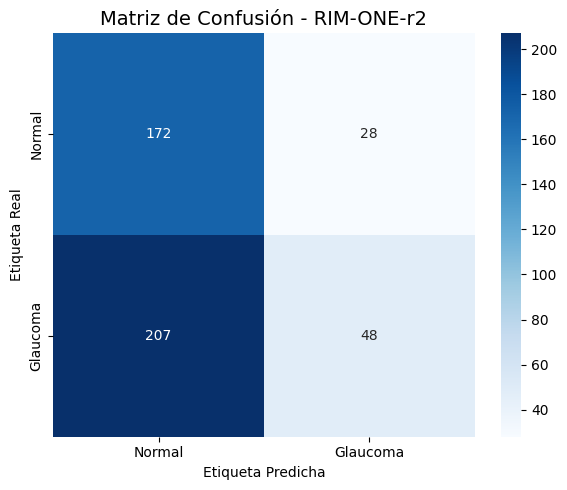

Normal clasificado como normal (TN): 172
Normal clasificado como glaucoma (FP): 28
Glaucoma clasificado como normal (FN): 207
Glaucoma clasificado como glaucoma (TP): 48

Accuracy: 0.48
Precisión (PPV): 0.63
Sensibilidad (TPR / Recall): 0.19
Especificidad (TNR): 0.86


In [10]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from tensorflow.keras.models import load_model

# Cargar el mejor modelo guardado (opcional, si no lo tienes cargado ya)
model = load_model("/Users/valeriabaz/Desktop/best_model_realista.h5")

def plot_confusion_matrix(model, generator, class_names=None, threshold=0.5):
    """
    Genera y muestra la matriz de confusión con métricas adicionales.

    Parameters:
    - model: modelo entrenado de Keras
    - generator: generador de datos (con generator.classes disponible)
    - class_names: lista de etiquetas de clases, por ejemplo ["Normal", "Glaucoma"]
    - threshold: umbral de clasificación binaria
    """
    # Etiquetas verdaderas y predichas
    y_true = generator.classes
    y_pred_probs = model.predict(generator, verbose=0)
    y_pred = (y_pred_probs > threshold).astype(int).flatten()

    # Matriz de confusión
    cm = confusion_matrix(y_true, y_pred)

    # Asegurar etiquetas si no se pasan
    if class_names is None:
        class_names = list(generator.class_indices.keys())

    # Visualización con seaborn
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.title("Matriz de Confusión - RIM-ONE-r2", fontsize=14)
    plt.xlabel("Etiqueta Predicha")
    plt.ylabel("Etiqueta Real")
    plt.tight_layout()
    plt.show(block=True)

    # Desempaquetar para métricas adicionales
    tn, fp, fn, tp = cm.ravel()

    # Métricas clave
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) else 0
    recall = tp / (tp + fn) if (tp + fn) else 0
    specificity = tn / (tn + fp) if (tn + fp) else 0

    # Mostrar métricas
    print(f"Normal clasificado como normal (TN): {tn}")
    print(f"Normal clasificado como glaucoma (FP): {fp}")
    print(f"Glaucoma clasificado como normal (FN): {fn}")
    print(f"Glaucoma clasificado como glaucoma (TP): {tp}")
    print(f"\nAccuracy: {accuracy:.2f}")
    print(f"Precisión (PPV): {precision:.2f}")
    print(f"Sensibilidad (TPR / Recall): {recall:.2f}")
    print(f"Especificidad (TNR): {specificity:.2f}")

plot_confusion_matrix(model, rimone_generator, class_names=["Normal", "Glaucoma"])

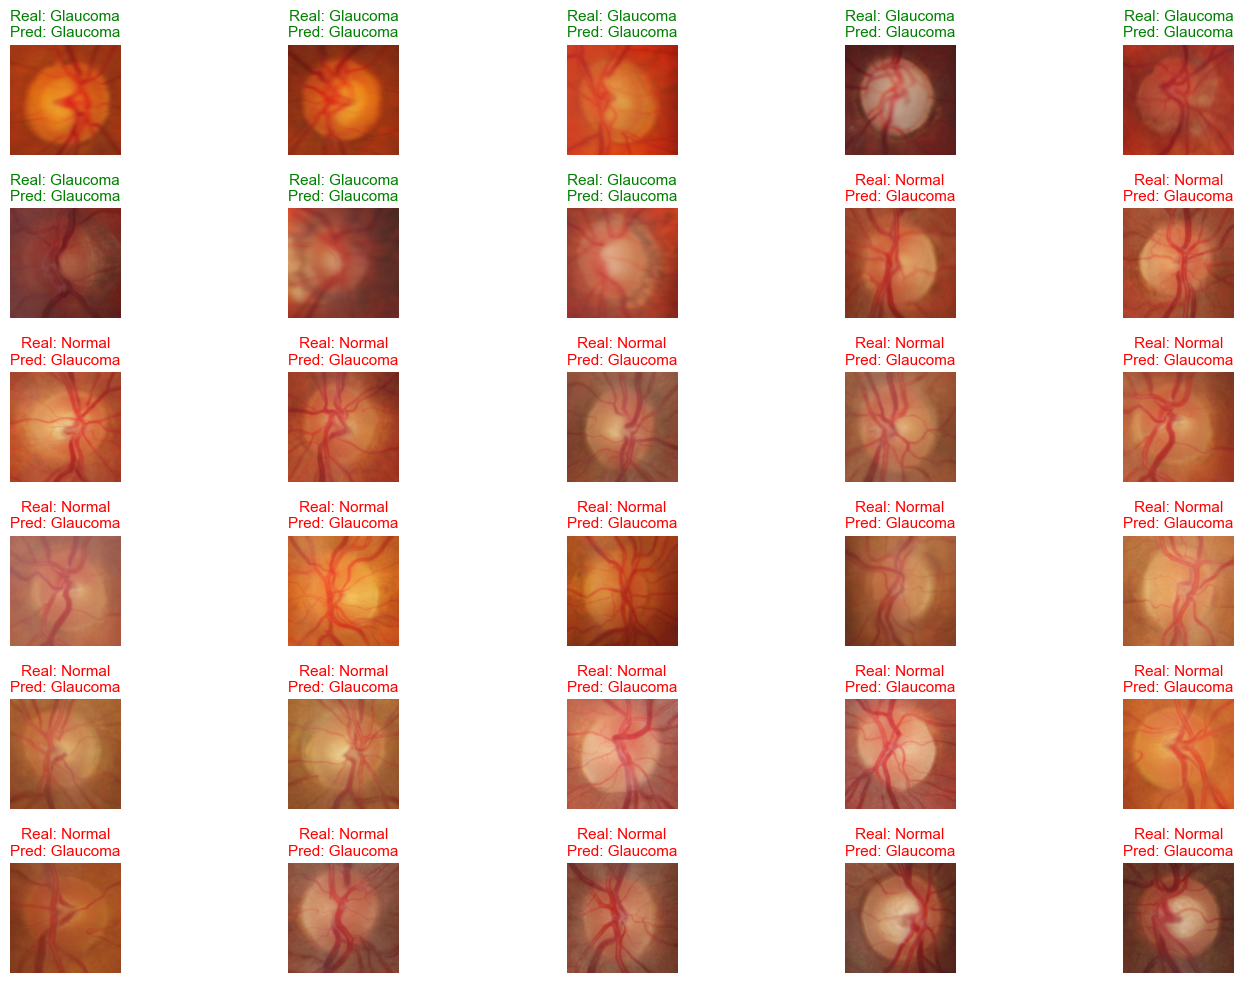

In [19]:
import matplotlib.pyplot as plt
import numpy as np

def display_predictions_from_generator(model, generator, class_names=None, num_images=30):
    # Obtener un batch del generador (asegúrate de que shuffle=False en su creación)
    images, labels = next(generator)

    # Hacer predicciones
    preds_probs = model.predict(images, verbose=0)
    preds_binary = (preds_probs > 0.5).astype(int).flatten()

    # Obtener nombres de clase del generador si no se han proporcionado
    if class_names is None:
        class_names = list(generator.class_indices.keys())

    # Convertir imágenes para visualización si están en [0, 1] o preprocesadas
    images_vis = images.copy()
    if images_vis.min() < 0:  # Imagen preprocesada tipo VGG16 (mean subtracted)
        images_vis = np.clip(images_vis + [103.939, 116.779, 123.68], 0, 255)
        images_vis = images_vis[..., ::-1]  # BGR → RGB
    images_vis = np.clip(images_vis, 0, 255).astype("uint8")

    # Mostrar imágenes
    plt.figure(figsize=(15, 10))
    for i in range(min(num_images, len(images_vis))):
        true_label = class_names[int(labels[i])]
        pred_label = class_names[int(preds_binary[i])]
        title_color = "green" if true_label == pred_label else "red"

        plt.subplot(6, 5, i + 1)
        plt.imshow(images_vis[i])
        plt.title(f"Real: {true_label}\nPred: {pred_label}", color=title_color, fontsize=11)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

display_predictions_from_generator(model, rimone_generator)

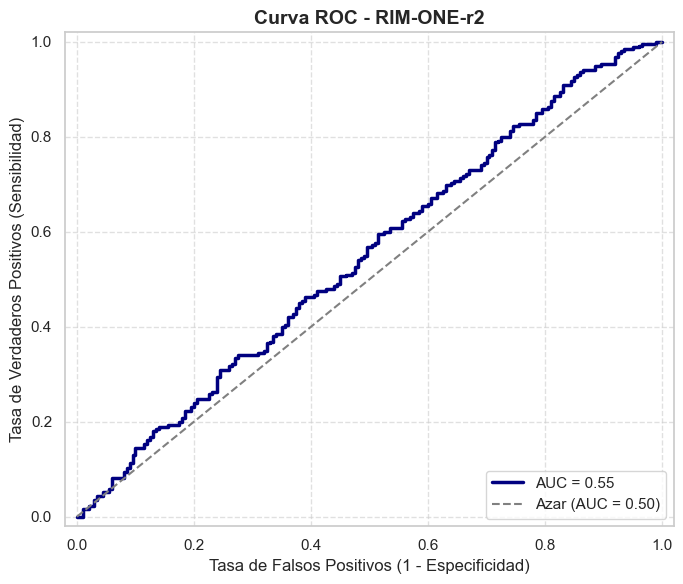

AUC-ROC RIM-ONE-r2: 0.5467
Umbral óptimo (Youden): 0.04


In [11]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Datos
y_true_rimone = rimone_generator.classes
y_pred_probs_rimone = model.predict(rimone_generator, verbose=0).flatten()

# Curva ROC
fpr_rimone, tpr_rimone, thresholds_rimone = roc_curve(y_true_rimone, y_pred_probs_rimone)
auc_rimone = auc(fpr_rimone, tpr_rimone)

# Youden J
j_scores_rimone = tpr_rimone - fpr_rimone
j_best_idx_rimone = np.argmax(j_scores_rimone)
best_thresh_rimone = thresholds_rimone[j_best_idx_rimone]
best_fpr_rimone = fpr_rimone[j_best_idx_rimone]
best_tpr_rimone = tpr_rimone[j_best_idx_rimone]

# Estilo
sns.set(style="whitegrid")

# Gráfico
plt.figure(figsize=(7, 6))
plt.plot(fpr_rimone, tpr_rimone, color='navy', lw=2.5, label=f'AUC = {auc_rimone:.2f}')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', lw=1.5, label='Azar (AUC = 0.50)')

# Ejes
plt.xlabel('Tasa de Falsos Positivos (1 - Especificidad)', fontsize=12)
plt.ylabel('Tasa de Verdaderos Positivos (Sensibilidad)', fontsize=12)
plt.title('Curva ROC - RIM-ONE-r2', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Resultado
print(f"AUC-ROC RIM-ONE-r2: {auc_rimone:.4f}")
print(f"Umbral óptimo (Youden): {best_thresh_rimone:.2f}")

# <span style="color:violet; font-size:28px"> Zonas más determinantes del diagnóstico emitido por la red visualizando una imagen


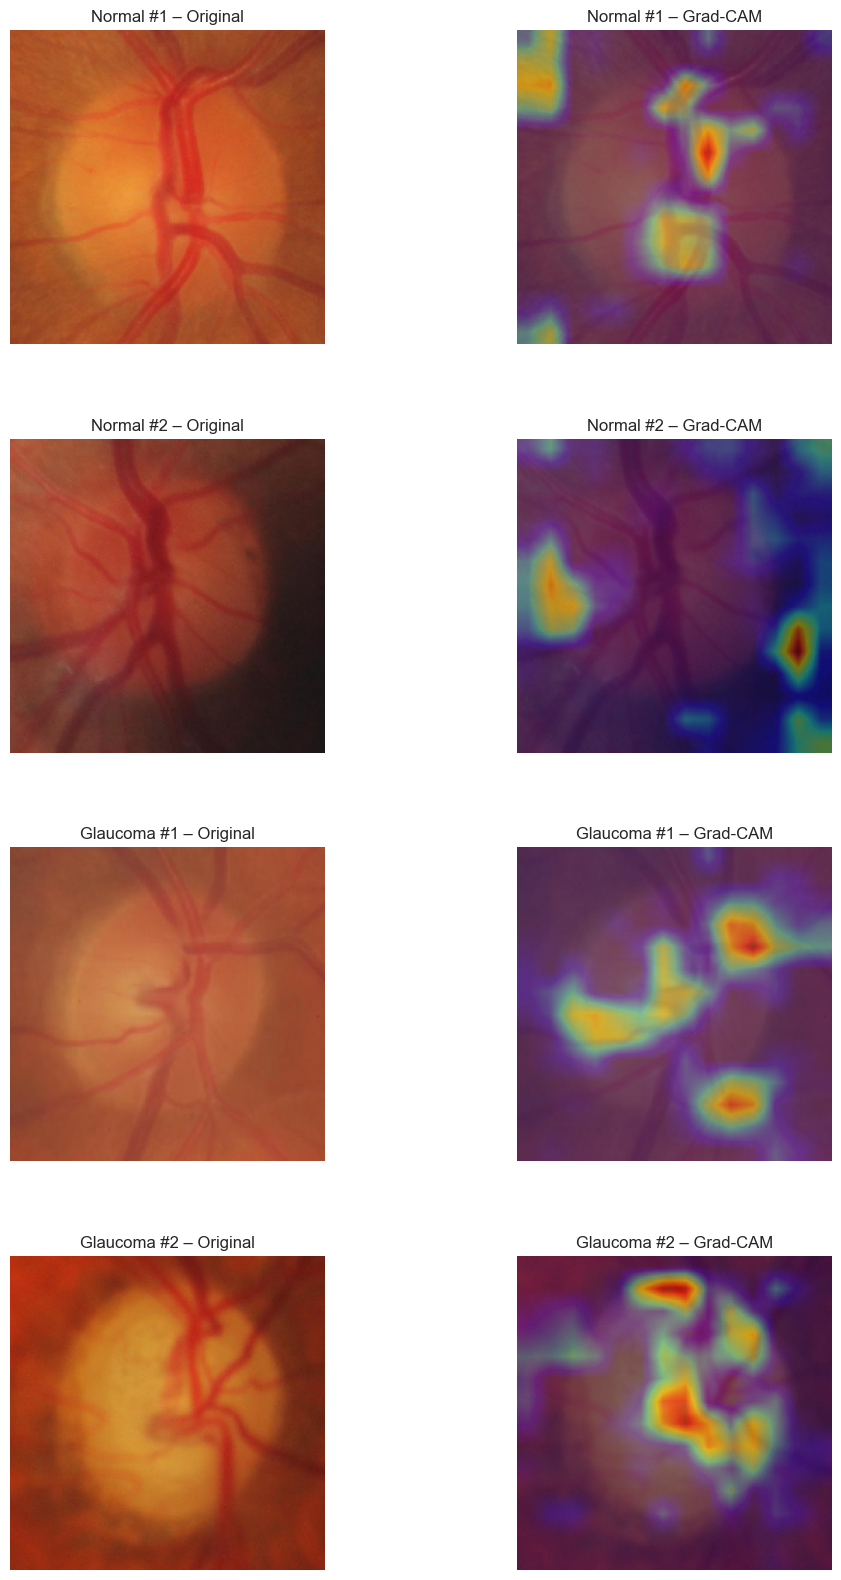

In [12]:
import os
import random

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import load_model, Model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.vgg16 import preprocess_input

# 1) Carga tu modelo entrenado
model = load_model("/Users/valeriabaz/Desktop/best_model_realista.h5")

# 2) Nombre de la última capa convolucional
last_conv_layer_name = 'block5_conv3'

# 3) Construye el modelo intermedio para Grad-CAM
grad_model = Model(
    inputs  = model.input,
    outputs = [model.get_layer(last_conv_layer_name).output,
               model.output]
)

def compute_gradcam(img_path: str, positive: bool = True, eps: float = 1e-8):
    # a) Carga la imagen y conserva una copia “raw” para mostrar
    pil_img       = image.load_img(img_path, target_size=(224,224))
    raw_img_array = image.img_to_array(pil_img).astype('uint8')

    # b) Prepara la entrada del modelo
    x = image.img_to_array(pil_img)     # float32, RGB
    x = np.expand_dims(x, axis=0)       # dim batch
    x = preprocess_input(x)             # BGR + resta medias

    # c) Forward + cálculos de gradiente
    with tf.GradientTape() as tape:
        conv_outputs, preds = grad_model(x)
        # preds[:,0] = P(glaucoma). Si queremos "Normal", invertimos la señal
        loss = preds[:,0] if positive else -preds[:,0]
    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0,1,2))

    # d) Pondera las activaciones con los gradientes
    conv_map = conv_outputs[0].numpy()
    for i in range(pooled_grads.shape[-1]):
        conv_map[..., i] *= pooled_grads[i].numpy()

    # e) Crea y normaliza el heatmap
    heatmap = np.mean(conv_map, axis=-1)
    heatmap = np.maximum(heatmap, 0)
    heatmap /= (heatmap.max() + eps)

    # f) Upsample a 224×224
    heatmap = tf.image.resize(
        heatmap[..., np.newaxis],
        (224,224),
        method='bilinear'
    ).numpy().squeeze()

    return heatmap, raw_img_array

# 4) Muestrea 2 imágenes de cada clase
base_dir = '/Users/valeriabaz/Desktop/Dataset-4 MIAG 2'
samples = {}
for cls_name in ['Normal', 'Glaucoma']:
    folder = os.path.join(base_dir, cls_name)
    jpgs   = [f for f in os.listdir(folder) if f.lower().endswith('.jpg')]
    samples[cls_name] = random.sample(jpgs, k=2)

# 5) Dibuja todas en una sola figura con subplots
fig, axes = plt.subplots(4, 2, figsize=(12, 20))
plt.subplots_adjust(hspace=0.3)

row = 0
for cls_name, file_list in samples.items():
    positive = (cls_name == 'Glaucoma')
    for idx, img_file in enumerate(file_list, start=1):
        img_path = os.path.join(base_dir, cls_name, img_file)
        heatmap, raw = compute_gradcam(img_path, positive=positive)

        # Columna 0: Original
        ax0 = axes[row, 0]
        ax0.imshow(raw)
        ax0.set_title(f"{cls_name} #{idx} – Original")
        ax0.axis('off')

        # Columna 1: Grad-CAM
        ax1 = axes[row, 1]
        ax1.imshow(raw)
        ax1.imshow(heatmap, cmap='jet', alpha=0.4)
        ax1.set_title(f"{cls_name} #{idx} – Grad-CAM")
        ax1.axis('off')

        row += 1

plt.show()

# <span style="color:violet; font-size:28px"> Diferencia de rendimiento del modelo en los diferentes conjuntos de datos


In [14]:
print(f"AUC en ACRIMA: {roc_auc:.4f}")
print(f"AUC en RIM-ONE-r2: {auc_rimone:.4f}")

AUC en ACRIMA: 0.9710
AUC en RIM-ONE-r2: 0.5467


In [15]:
print(f"Diferencia absoluta de AUCs: {abs(roc_auc - auc_rimone):.4f}")

Diferencia absoluta de AUCs: 0.4243


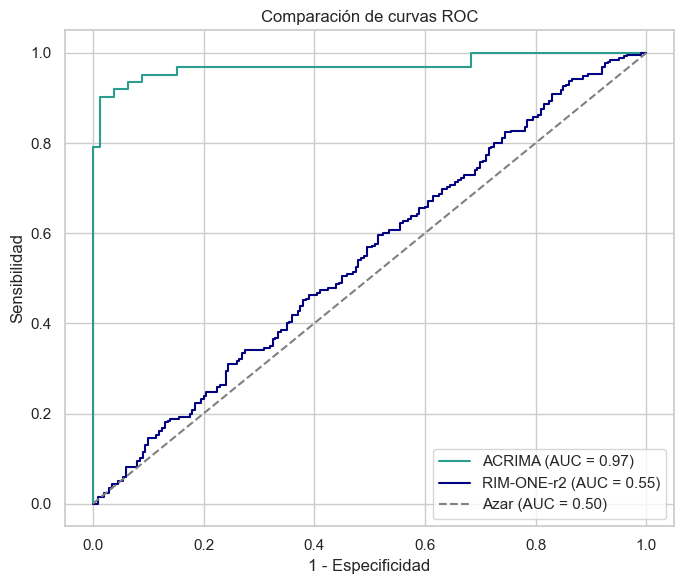

In [17]:
plt.figure(figsize=(7, 6))

# Usar fpr y tpr para ACRIMA
plt.plot(fpr, tpr, label=f'ACRIMA (AUC = {roc_auc:.2f})', color='#2a9d8f')

plt.plot(fpr_rimone, tpr_rimone, label=f'RIM-ONE-r2 (AUC = {auc_rimone:.2f})', color='navy')

# Línea de azar
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Azar (AUC = 0.50)')

# Configuración
plt.xlabel('1 - Especificidad')
plt.ylabel('Sensibilidad')
plt.title('Comparación de curvas ROC')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()

# <span style="color:violet; font-size:28px"> Comparación utilizando una métrica diferente

In [20]:
from sklearn.metrics import f1_score

# Para ACRIMA (usa las variables ya existentes)
f1_acrima = f1_score(y_true, y_pred)

# Para RIM-ONE-r2
y_pred_rimone = (y_pred_probs_rimone > 0.5).astype(int)
f1_rimone = f1_score(y_true_rimone, y_pred_rimone)

print(f"F1-score en ACRIMA: {f1_acrima:.4f}")
print(f"F1-score en RIM-ONE-r2: {f1_rimone:.4f}")


F1-score en ACRIMA: 0.9008
F1-score en RIM-ONE-r2: 0.2900
